In [ ]:
# Customer Churn Analysis
# Step 1: Import the libraries we need

import pandas as pd
from pathlib import Path

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:
# Step 2: Load the customer churn dataset

project_dir = Path.cwd().parent
data_path = project_dir / "data" / "WA_Fn-UseC_-Telco-Customer-Churn.csv"

df = pd.read_csv(data_path)

print("Dataset loaded successfully!")


Dataset loaded successfully!


In [3]:
# Step 3: Preview the first five rows

df.head()


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:

# Step 4: Check the dataset dimensions

df.shape


(7043, 21)

In [5]:

# Step 5: Display all column names

df.columns.tolist()


['customerID',
 'gender',
 'SeniorCitizen',
 'Partner',
 'Dependents',
 'tenure',
 'PhoneService',
 'MultipleLines',
 'InternetService',
 'OnlineSecurity',
 'OnlineBackup',
 'DeviceProtection',
 'TechSupport',
 'StreamingTV',
 'StreamingMovies',
 'Contract',
 'PaperlessBilling',
 'PaymentMethod',
 'MonthlyCharges',
 'TotalCharges',
 'Churn']

In [6]:

# Step 6: Check for missing values

df.isnull().sum()


customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [7]:

# Step 7: Check the data types of each column

df.dtypes


customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object

In [8]:

# Step 8: Identify TotalCharges values that cannot be converted to numbers

total_charges_numeric = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

invalid_total_charges = total_charges_numeric.isna().sum()

print("Invalid TotalCharges values:", invalid_total_charges)

df.loc[
    total_charges_numeric.isna(),
    ["customerID", "tenure", "TotalCharges"]
]


Invalid TotalCharges values: 11


,customerID,tenure,TotalCharges
488,4472-LVYGI,0,
753,3115-CZMZD,0,
936,5709-LVOEQ,0,
1082,4367-NUYAO,0,
1340,1371-DWPAZ,0,
3331,7644-OMVMY,0,
3826,3213-VVOLG,0,
4380,2520-SGTTA,0,
5218,2923-ARZLG,0,
6670,4075-WKNIU,0,


In [9]:

# Step 9: Create a cleaned copy and convert TotalCharges to numeric

df_clean = df.copy()

df_clean["TotalCharges"] = pd.to_numeric(
    df_clean["TotalCharges"],
    errors="coerce"
)

print("Original dataset rows:", len(df))
print("Cleaned dataset rows:", len(df_clean))
print("Missing TotalCharges after conversion:", df_clean["TotalCharges"].isna().sum())

df_clean[["customerID", "tenure", "TotalCharges"]].head()


Original dataset rows: 7043
Cleaned dataset rows: 7043
Missing TotalCharges after conversion: 11


,customerID,tenure,TotalCharges
0,7590-VHVEG,1,29.85
1,5575-GNVDE,34,1889.50
2,3668-QPYBK,2,108.15
3,7795-CFOCW,45,1840.75
4,9237-HQITU,2,151.65


In [10]:

# Step 10: Verify the cleaned data types

df_clean.dtypes


customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges        float64
Churn                   str
dtype: object

In [11]:

# Step 11: Check for duplicate customer records

duplicate_count = df_clean["customerID"].duplicated().sum()

print("Duplicate customer IDs:", duplicate_count)


Duplicate customer IDs: 0


In [12]:

# Step 12: Count customers who churned and stayed

df_clean["Churn"].value_counts()


Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [13]:

# Step 13: Calculate the overall customer churn rate

churn_rate = (df_clean["Churn"] == "Yes").mean() * 100

print(f"Overall churn rate: {churn_rate:.2f}%")


Overall churn rate: 26.54%


In [14]:

# Step 14: Analyze customer churn by contract type

churn_by_contract = pd.crosstab(
    df_clean["Contract"],
    df_clean["Churn"]
)

churn_by_contract


Churn,No,Yes
Contract,,
Month-to-month,2220,1655
One year,1307,166
Two year,1647,48


In [15]:

# Step 15: Calculate churn rates by contract type

churn_rate_by_contract = (
    df_clean.groupby("Contract")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .round(2)
    .sort_values(ascending=False)
)

churn_rate_by_contract


Contract
Month-to-month    42.71
One year          11.27
Two year           2.83
Name: Churn, dtype: float64

Step 16 — Interpret our findings
CHURN RATE BY CONTRACT TYPE

Month-to-month
42.71%

One year
11.27%

Two year
2.83%

In [18]:

# Step 17: Compare tenure for customers who churned and stayed

df_clean.groupby("Churn")["tenure"].agg(
    ["count", "mean", "median", "min", "max"]
).round(2)


,count,mean,median,min,max
Churn,,,,,
No,5174,37.57,38.0,0,72
Yes,1869,17.98,10.0,1,72


Step 18 — Interpret the tenure results
Average customer tenure

Customers who stayed
37.57 months
Median: 38 months

Customers who churned
17.98 months
Median: 10 months

Customers who churned had an average tenure about 19.59 months shorter than customers who stayed.

In [19]:

# Step 19: Group customers by tenure

tenure_bins = [0, 12, 24, 48, 72]
tenure_labels = [
    "0-12 months",
    "13-24 months",
    "25-48 months",
    "49-72 months"
]

df_clean["TenureGroup"] = pd.cut(
    df_clean["tenure"],
    bins=tenure_bins,
    labels=tenure_labels,
    include_lowest=True
)

df_clean[["tenure", "TenureGroup"]].head(10)


,tenure,TenureGroup
0,1,0-12 months
1,34,25-48 months
2,2,0-12 months
3,45,25-48 months
4,2,0-12 months
5,8,0-12 months
6,22,13-24 months
7,10,0-12 months
8,28,25-48 months
9,62,49-72 months


In [20]:

# Step 20: Calculate churn rates by tenure group

churn_rate_by_tenure = (
    df_clean.groupby("TenureGroup", observed=False)["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .round(2)
)

churn_rate_by_tenure


TenureGroup
0-12 months     47.44
13-24 months    28.71
25-48 months    20.39
49-72 months     9.51
Name: Churn, dtype: float64

Step 21 — Interpret the tenure findings
The results show that churn is highest among customers in their first 12 months, and the rate decreases as tenure increases.

Churn rate by customer tenure
0–12 months
47.44%

13–24 months
28.71%

25–48 months
20.39%

49–72 months
9.51%

In [21]:

# Step 21: Count churned and retained customers by payment method

churn_by_payment = pd.crosstab(
    df_clean["PaymentMethod"],
    df_clean["Churn"]
)

churn_by_payment


Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),1286,258
Credit card (automatic),1290,232
Electronic check,1294,1071
Mailed check,1304,308


Step 22 — Interpret the payment-method counts
The table shows these results:

Payment method	              Stayed	Churned	  Total
Bank transfer (automatic)	   1,286	258	      1,544
Credit card (automatic)        1,290	232	      1,522
Electronic check	           1,294	1,071	  2,365
Mailed check	               1,304	308	      1,612

Initial observation: Electronic check has substantially more churned customers than the other payment methods. But we need to compare percentages because the group sizes differ.

In [22]:

# Step 22: Calculate churn rates by payment method

churn_rate_by_payment = (
    df_clean.groupby("PaymentMethod")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .round(2)
    .sort_values(ascending=False)
)

churn_rate_by_payment


PaymentMethod
Electronic check             45.29
Mailed check                 19.11
Bank transfer (automatic)    16.71
Credit card (automatic)      15.24
Name: Churn, dtype: float64

Step 23 — Interpret churn by payment method

- Electronic check: 45.29% churn — the highest rate among the four payment methods.
- Mailed check: 19.11% churn.
- Automatic bank transfer: 16.71% churn.
- Automatic credit card: 15.24% churn — the lowest rate.

Customers using electronic checks have nearly three times the churn rate of customers paying automatically by credit card.

Business implication: The company could investigate whether electronic-check customers experience different billing processes, service preferences, or customer characteristics. It could also test whether offering convenient automatic payment options improves retention. These results show an association, not proof that payment method causes churn.

In [23]:

# Step 24: Count churned and retained customers by internet service

churn_by_internet = pd.crosstab(
    df_clean["InternetService"],
    df_clean["Churn"]
)

churn_by_internet


Churn,No,Yes
InternetService,,
DSL,1962,459
Fiber optic,1799,1297
No,1413,113


In [24]:

# Step 25: Calculate churn rates by internet service

churn_rate_by_internet = (
    df_clean.groupby("InternetService")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .round(2)
    .sort_values(ascending=False)
)

churn_rate_by_internet


InternetService
Fiber optic    41.89
DSL            18.96
No              7.40
Name: Churn, dtype: float64

Step 26 — Interpret churn by internet service

- Fiber optic: 41.89% churn — the highest rate among the three groups.
- DSL: 18.96% churn.
- No internet service: 7.40% churn — the lowest rate.
The churn rate for fiber optic customers is approximately 2.2 times that of DSL customers and 5.7 times that of customers without internet service.

Business implication: The company should investigate the fiber optic customer experience, including service reliability, pricing, installation, and customer support. These are possible areas to examine, not confirmed explanations for the higher churn rate.

In [25]:

# Step 27: Compare monthly charges for customers who churned and stayed

df_clean.groupby("Churn")["MonthlyCharges"].agg(
    ["count", "mean", "median", "min", "max"]
).round(2)


,count,mean,median,min,max
Churn,,,,,
No,5174,61.27,64.43,18.25,118.75
Yes,1869,74.44,79.65,18.85,118.35


Step 28 — Interpret monthly charges

Monthly charges comparison
Customers who stayed - 61.27
Median: 64.43

Customers who churned - 74.44
Median: 79.65

Customers who churned paid an average of 13.17 more per month than customers who stayed, in the dataset's currency units.

- Customers who churned had higher average and median monthly charges.
- The difference suggests that higher monthly charges may be associated with churn.
- However, we cannot conclude that price alone causes customers to leave. Contract type, internet service, and other customer characteristics may also contribute.
Business implication: The company could investigate whether customers paying higher monthly charges receive sufficient value for their plans, and whether pricing, service quality, or plan suitability contributes to dissatisfaction.

In [26]:

# Step 29: Group customers by monthly charges

charge_bins = [0, 35, 70, 100, float("inf")]
charge_labels = [
    "0-35",
    "35-70",
    "70-100",
    "100+"
]

df_clean["MonthlyChargeGroup"] = pd.cut(
    df_clean["MonthlyCharges"],
    bins=charge_bins,
    labels=charge_labels,
    include_lowest=True
)

df_clean[["MonthlyCharges", "MonthlyChargeGroup"]].head(10)


,MonthlyCharges,MonthlyChargeGroup
0,29.85,0-35
1,56.95,35-70
2,53.85,35-70
3,42.30,35-70
4,70.70,70-100
5,99.65,70-100
6,89.10,70-100
7,29.75,0-35
8,104.80,100+
9,56.15,35-70


In [27]:

# Step 30: Calculate churn rates by monthly charge group

churn_rate_by_charge = (
    df_clean.groupby("MonthlyChargeGroup", observed=False)["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .round(2)
)

churn_rate_by_charge


MonthlyChargeGroup
0-35      10.89
35-70     23.94
70-100    37.82
100+      28.05
Name: Churn, dtype: float64

Step 31 — Interpret churn by monthly charge group
Churn rate by monthly charges

0–35 - 10.89%
35–70 - 23.94%
70–100 - 37.82%
100+ - 28.05%

Monthly charge units follow the dataset's original currency; the groups are based on the MonthlyCharges column.

- 0–35: 10.89% churn — the lowest rate.
- 35–70: 23.94% churn.
- 70–100: 37.82% churn — the highest rate.
- 100+: 28.05% churn.
Churn rises across the first three charge ranges, but drops in the highest range. Therefore, the relationship is not simply “the more customers pay, the more likely they are to churn.”

The 70–100 group has the highest churn rate. Differences in contract type, internet service, and other customer characteristics could help explain this pattern.

Business implication: Investigate customers in the 70–100 range to understand whether their service bundles, pricing, or contract arrangements are associated with higher churn.

In [28]:

# Step 32: Compare churn rates by contract and internet service

churn_by_contract_internet = (
    df_clean.pivot_table(
        index="Contract",
        columns="InternetService",
        values="Churn",
        aggfunc=lambda x: (x == "Yes").mean() * 100,
        observed=False
    )
    .round(2)
)

churn_by_contract_internet


InternetService,DSL,Fiber optic,No
Contract,,,
Month-to-month,32.22,54.61,18.89
One year,9.30,19.29,2.47
Two year,1.91,7.23,0.78


Step 33 — Interpret the combined results

Contract type       DSL         Fiber optic     No internet
Month-to-month      32.22%	    54.61%	        18.89%
One year	        9.30%	    19.29%	        2.47%
Two year	        1.91%	    7.23%	        0.78%

Key findings
- Highest churn: Month-to-month fiber optic customers, at 54.61%.
- Lowest churn: Two-year customers without internet service, at 0.78%.
- Contract pattern: Churn rates are lower for longer-term contracts across all three internet service categories.
- Internet service pattern: Fiber optic customers have higher churn rates than DSL customers within every contract category.

These results suggest that month-to-month fiber optic customers may be a particularly important segment for retention efforts. However, the analysis identifies associations, not causal effects, and we should check the number of customers in each segment before making strong recommendations.

In [29]:

# Step 34: Count customers by contract and internet service

customer_counts_by_segment = pd.crosstab(
    df_clean["Contract"],
    df_clean["InternetService"]
)

customer_counts_by_segment


InternetService,DSL,Fiber optic,No
Contract,,,
Month-to-month,1223,2128,524
One year,570,539,364
Two year,628,429,638


Step 35 — Interpret the segment sizes

Contract type   DSL	    Fiber optic	    No internet
Month-to-month	1,223	2,128	        524
One year	    570	    539	            364
Two year	    628	    429	            638

The highest-churn segment, month-to-month fiber optic, contains 2,128 customers. That's a substantial group, so its 54.61% churn rate is worth investigating.

The two-year fiber optic group has 429 customers, so its 7.23% rate is also useful, though it represents a smaller segment.


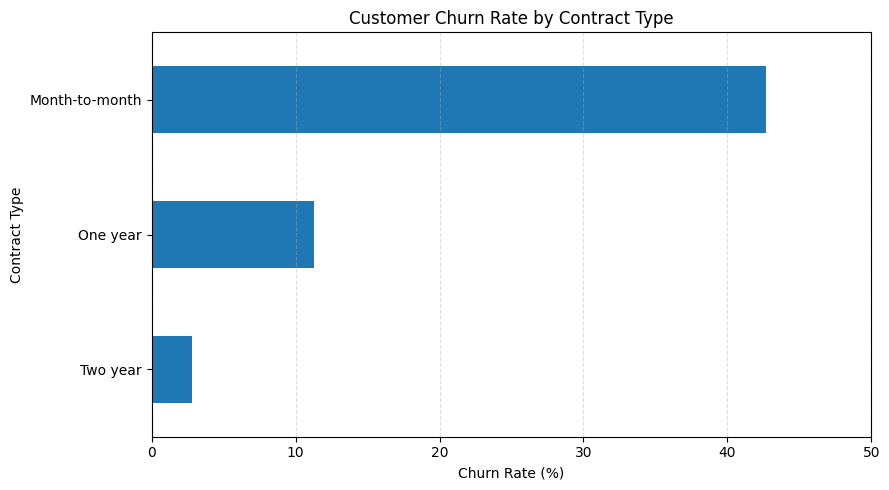

In [30]:

# Step 36: Visualize churn rates by contract type

import matplotlib.pyplot as plt

churn_rate_by_contract.sort_values().plot(
    kind="barh",
    figsize=(9, 5)
)

plt.title("Customer Churn Rate by Contract Type")
plt.xlabel("Churn Rate (%)")
plt.ylabel("Contract Type")
plt.xlim(0, 50)
plt.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


Step 36 — Review the chart
The chart shows the difference in churn rates by contract type:
Contract type	Churn rate
Month-to-month	42.71%
One year	    11.27%
Two year	    2.83%

The key takeaway: Month-to-month customers have a substantially higher churn rate than customers with longer-term contracts.

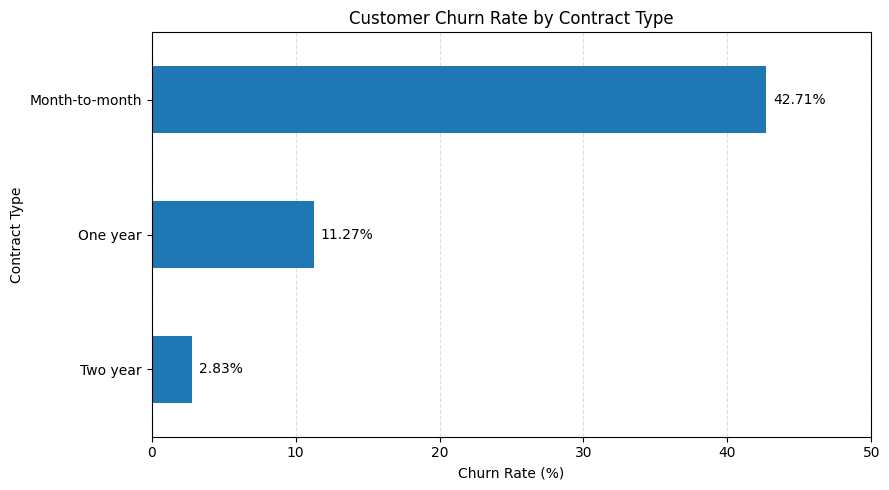

In [31]:

# Step 37: Improve the contract churn chart with data labels

import matplotlib.pyplot as plt

contract_rates = churn_rate_by_contract.sort_values()

ax = contract_rates.plot(
    kind="barh",
    figsize=(9, 5)
)

ax.set_title("Customer Churn Rate by Contract Type")
ax.set_xlabel("Churn Rate (%)")
ax.set_ylabel("Contract Type")
ax.set_xlim(0, 50)
ax.grid(axis="x", linestyle="--", alpha=0.4)
ax.set_axisbelow(True)

# Add percentage labels at the end of each bar
for bar in ax.patches:
    width = bar.get_width()
    ax.annotate(
        f"{width:.2f}%",
        (width, bar.get_y() + bar.get_height() / 2),
        xytext=(5, 0),
        textcoords="offset points",
        va="center"
    )

plt.tight_layout()
plt.show()


In [32]:

# Step 38: Save the contract churn chart

from pathlib import Path

project_dir = Path.cwd().parent

output_dir = project_dir / "python" / "charts"
output_dir.mkdir(parents=True, exist_ok=True)

chart_path = output_dir / "churn_rate_by_contract.png"

ax.figure.savefig(
    chart_path,
    dpi=300,
    bbox_inches="tight"
)

print(f"Chart saved to: {chart_path}")


Chart saved to: /Users/eironbatac/Desktop/DataAnalyticsPortfolio/projects/customer-churn-analysis/python/charts/churn_rate_by_contract.png


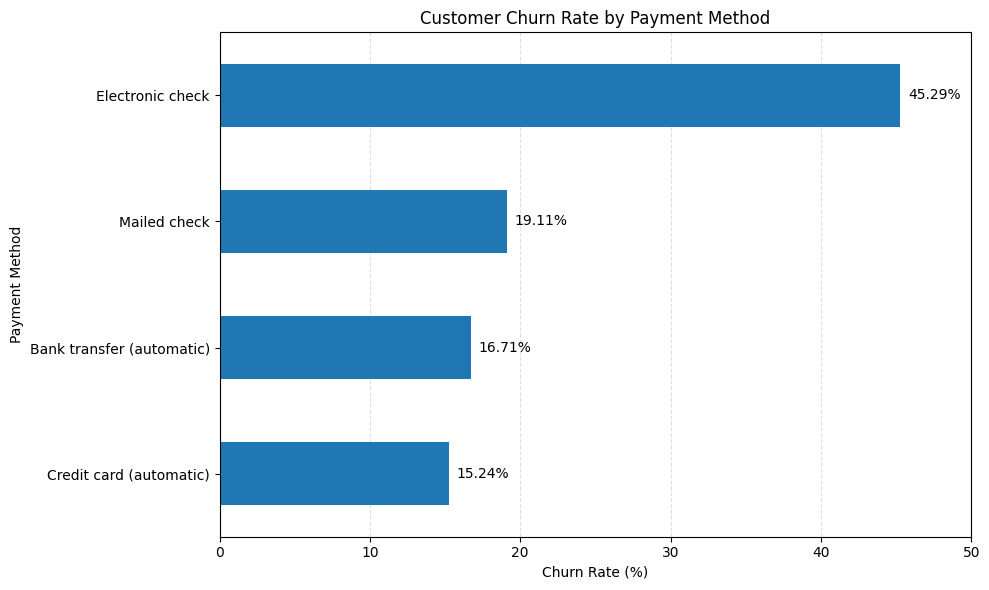

Chart saved successfully to: /Users/eironbatac/Desktop/DataAnalyticsPortfolio/projects/customer-churn-analysis/python/charts/churn_rate_by_payment.png


In [ ]:

# Step 39-41: Visualize and save customer churn rate by payment method

import matplotlib.pyplot as plt
from pathlib import Path

# Sort churn rates from lowest to highest for the horizontal chart
payment_churn_sorted = churn_rate_by_payment.sort_values()

# Create the chart
fig, ax = plt.subplots(figsize=(10, 6))

payment_churn_sorted.plot(
    kind="barh",
    ax=ax
)

# Add chart title and axis labels
ax.set_title("Customer Churn Rate by Payment Method")
ax.set_xlabel("Churn Rate (%)")
ax.set_ylabel("Payment Method")
ax.set_xlim(0, 50)

# Add gridlines
ax.grid(axis="x", linestyle="--", alpha=0.4)
ax.set_axisbelow(True)

# Add percentage labels to the bars
for index, value in enumerate(payment_churn_sorted):
    ax.text(
        value + 0.5,
        index,
        f"{value:.2f}%",
        va="center"
    )

# Locate the charts folder
chart_dir = Path.cwd().parent / "python" / "charts"
chart_dir.mkdir(parents=True, exist_ok=True)

# Save the chart
chart_path = chart_dir / "churn_rate_by_payment.png"

fig.tight_layout()
fig.savefig(
    chart_path,
    dpi=300,
    bbox_inches="tight"
)

# Display the chart and confirm the saved location
plt.show()

print(f"Chart saved successfully to: {chart_path}")


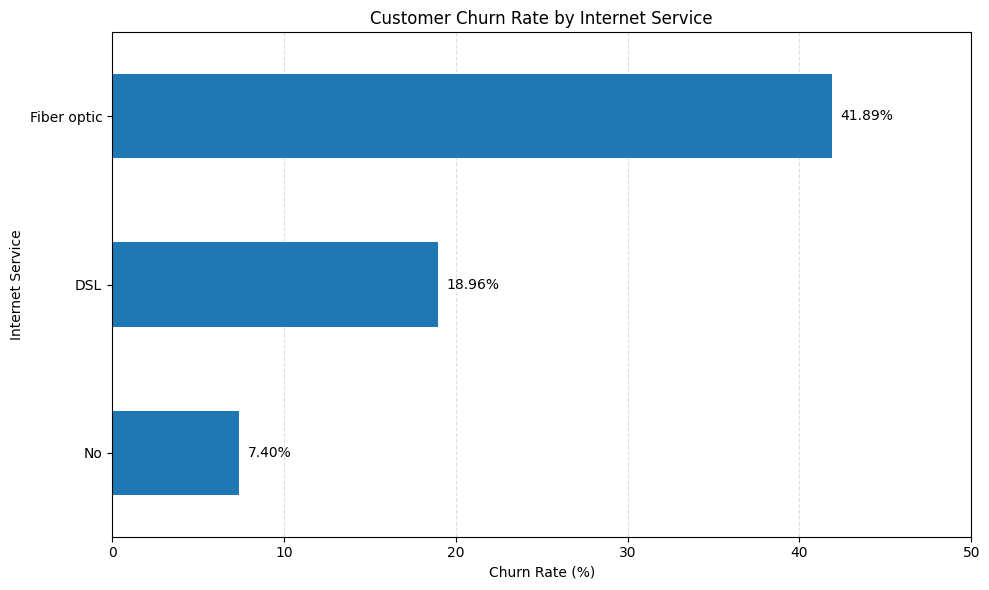

Chart saved successfully to: /Users/eironbatac/Desktop/DataAnalyticsPortfolio/projects/customer-churn-analysis/python/charts/churn_rate_by_internet.png


In [36]:

# Step 42: Visualize and save customer churn rate by internet service

import matplotlib.pyplot as plt
from pathlib import Path

# Sort churn rates from lowest to highest
internet_churn_sorted = churn_rate_by_internet.sort_values()

# Create the chart
fig, ax = plt.subplots(figsize=(10, 6))

internet_churn_sorted.plot(
    kind="barh",
    ax=ax
)

# Add chart title and labels
ax.set_title("Customer Churn Rate by Internet Service")
ax.set_xlabel("Churn Rate (%)")
ax.set_ylabel("Internet Service")
ax.set_xlim(0, 50)

# Add gridlines
ax.grid(axis="x", linestyle="--", alpha=0.4)
ax.set_axisbelow(True)

# Add percentage labels
for index, value in enumerate(internet_churn_sorted):
    ax.text(
        value + 0.5,
        index,
        f"{value:.2f}%",
        va="center"
    )

# Save the chart
chart_dir = Path.cwd().parent / "python" / "charts"
chart_dir.mkdir(parents=True, exist_ok=True)

chart_path = chart_dir / "churn_rate_by_internet.png"

fig.tight_layout()
fig.savefig(
    chart_path,
    dpi=300,
    bbox_inches="tight"
)

# Display and confirm
plt.show()

print(f"Chart saved successfully to: {chart_path}")


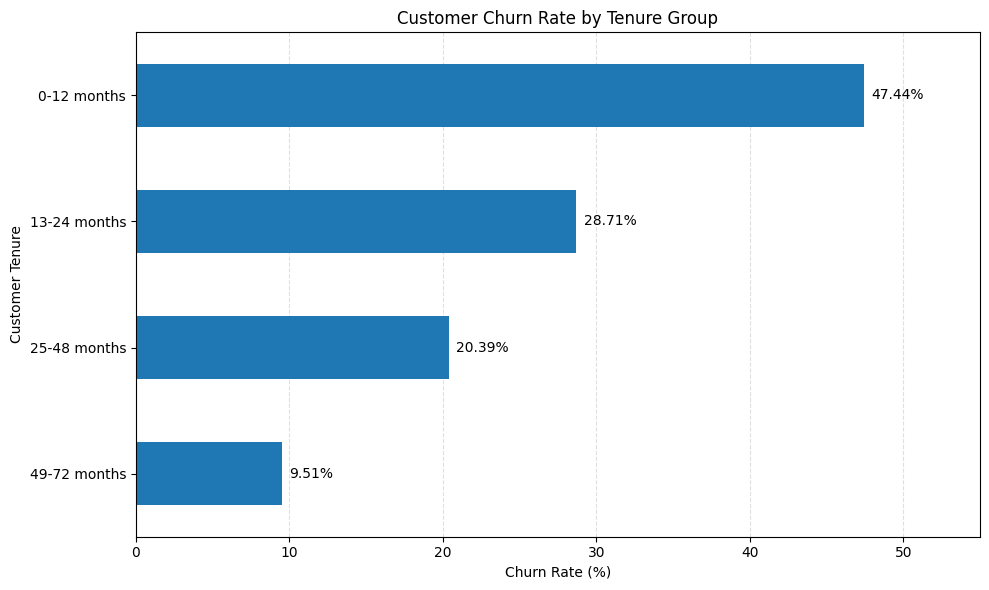

Chart saved successfully to: /Users/eironbatac/Desktop/DataAnalyticsPortfolio/projects/customer-churn-analysis/python/charts/churn_rate_by_tenure.png


In [37]:

# Step 43: Visualize and save customer churn rate by tenure group

import matplotlib.pyplot as plt
from pathlib import Path

# Sort churn rates from lowest to highest
tenure_churn_sorted = churn_rate_by_tenure.sort_values()

# Create the chart
fig, ax = plt.subplots(figsize=(10, 6))

tenure_churn_sorted.plot(
    kind="barh",
    ax=ax
)

# Add title and axis labels
ax.set_title("Customer Churn Rate by Tenure Group")
ax.set_xlabel("Churn Rate (%)")
ax.set_ylabel("Customer Tenure")
ax.set_xlim(0, 55)

# Add gridlines
ax.grid(axis="x", linestyle="--", alpha=0.4)
ax.set_axisbelow(True)

# Add percentage labels
for index, value in enumerate(tenure_churn_sorted):
    ax.text(
        value + 0.5,
        index,
        f"{value:.2f}%",
        va="center"
    )

# Save the chart
chart_dir = Path.cwd().parent / "python" / "charts"
chart_dir.mkdir(parents=True, exist_ok=True)

chart_path = chart_dir / "churn_rate_by_tenure.png"

fig.tight_layout()
fig.savefig(
    chart_path,
    dpi=300,
    bbox_inches="tight"
)

# Display and confirm
plt.show()

print(f"Chart saved successfully to: {chart_path}")


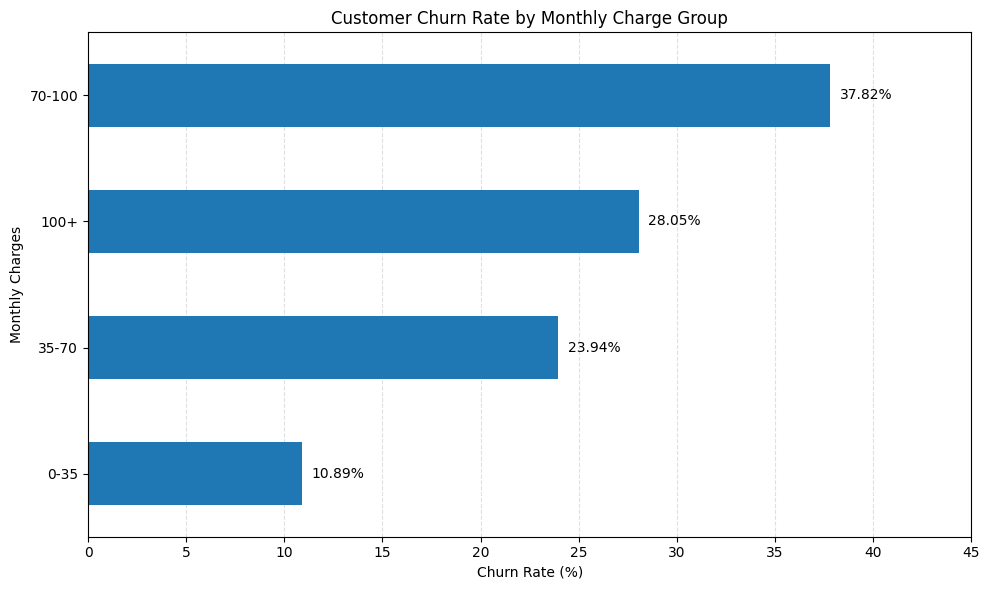

Chart saved successfully to: /Users/eironbatac/Desktop/DataAnalyticsPortfolio/projects/customer-churn-analysis/python/charts/churn_rate_by_monthly_charge.png


In [38]:

# Step 44: Visualize and save customer churn rate by monthly charge group

import matplotlib.pyplot as plt
from pathlib import Path

# Sort churn rates from lowest to highest
charge_churn_sorted = churn_rate_by_charge.sort_values()

# Create the chart
fig, ax = plt.subplots(figsize=(10, 6))

charge_churn_sorted.plot(
    kind="barh",
    ax=ax
)

# Add title and axis labels
ax.set_title("Customer Churn Rate by Monthly Charge Group")
ax.set_xlabel("Churn Rate (%)")
ax.set_ylabel("Monthly Charges")
ax.set_xlim(0, 45)

# Add gridlines
ax.grid(axis="x", linestyle="--", alpha=0.4)
ax.set_axisbelow(True)

# Add percentage labels
for index, value in enumerate(charge_churn_sorted):
    ax.text(
        value + 0.5,
        index,
        f"{value:.2f}%",
        va="center"
    )

# Save the chart
chart_dir = Path.cwd().parent / "python" / "charts"
chart_dir.mkdir(parents=True, exist_ok=True)

chart_path = chart_dir / "churn_rate_by_monthly_charge.png"

fig.tight_layout()
fig.savefig(
    chart_path,
    dpi=300,
    bbox_inches="tight"
)

# Display and confirm
plt.show()

print(f"Chart saved successfully to: {chart_path}")


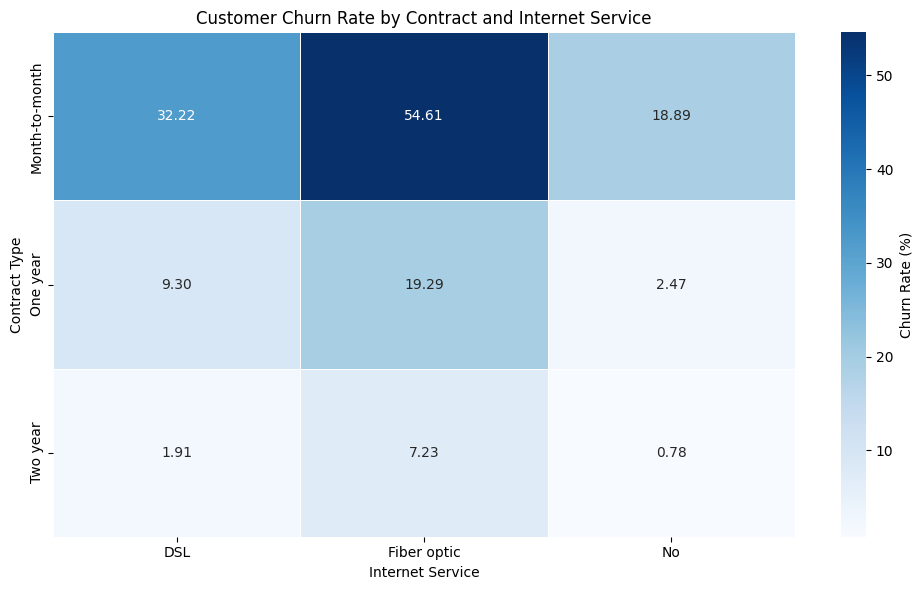

Chart saved successfully to: /Users/eironbatac/Desktop/DataAnalyticsPortfolio/projects/customer-churn-analysis/python/charts/churn_heatmap_contract_internet.png


In [39]:

# Step 45: Visualize churn rates by contract type and internet service

import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Calculate churn rates for each contract and internet service combination
churn_heatmap = pd.crosstab(
    [df_clean["Contract"], df_clean["InternetService"]],
    df_clean["Churn"],
    normalize="index"
)["Yes"] * 100

# Reshape results into a heatmap-friendly table
churn_heatmap = churn_heatmap.unstack()

# Create the heatmap
fig, ax = plt.subplots(figsize=(10, 6))

sns.heatmap(
    churn_heatmap,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    linewidths=0.5,
    cbar_kws={"label": "Churn Rate (%)"},
    ax=ax
)

ax.set_title("Customer Churn Rate by Contract and Internet Service")
ax.set_xlabel("Internet Service")
ax.set_ylabel("Contract Type")

# Save the chart
chart_dir = Path.cwd().parent / "python" / "charts"
chart_dir.mkdir(parents=True, exist_ok=True)

chart_path = chart_dir / "churn_heatmap_contract_internet.png"

fig.tight_layout()
fig.savefig(
    chart_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"Chart saved successfully to: {chart_path}")


In [40]:

# Step 46: Calculate churn rates by online security and tech support

churn_by_security_support = {}

for column in ["OnlineSecurity", "TechSupport"]:
    churn_rates = (
        df_clean.groupby(column, observed=True)["Churn"]
        .apply(lambda x: (x == "Yes").mean() * 100)
        .round(2)
        .sort_values(ascending=False)
    )

    churn_by_security_support[column] = churn_rates

    print(f"\nChurn Rate by {column} (%)")
    print(churn_rates)



Churn Rate by OnlineSecurity (%)
OnlineSecurity
No                     41.77
Yes                    14.61
No internet service     7.40
Name: Churn, dtype: float64

Churn Rate by TechSupport (%)
TechSupport
No                     41.64
Yes                    15.17
No internet service     7.40
Name: Churn, dtype: float64


Step 46 — Interpreting the results

1. Churn by online security
    No online security
    Customers with internet service
        -41.77%

    Has online security
        -14.61%

Difference: 27.16 percentage points.

2. Churn by tech support
    No tech support
    Customers with internet service
        -41.64%

    Has tech support
        -15.17%

Difference: 26.47 percentage points.

Customers without online security or tech support have substantially higher churn rates than those with these services. Customers with no internet service have a 7.40% churn rate in both comparisons, which is consistent with the categories in the dataset.

These results show an association, not proof that adding either service will directly prevent churn.

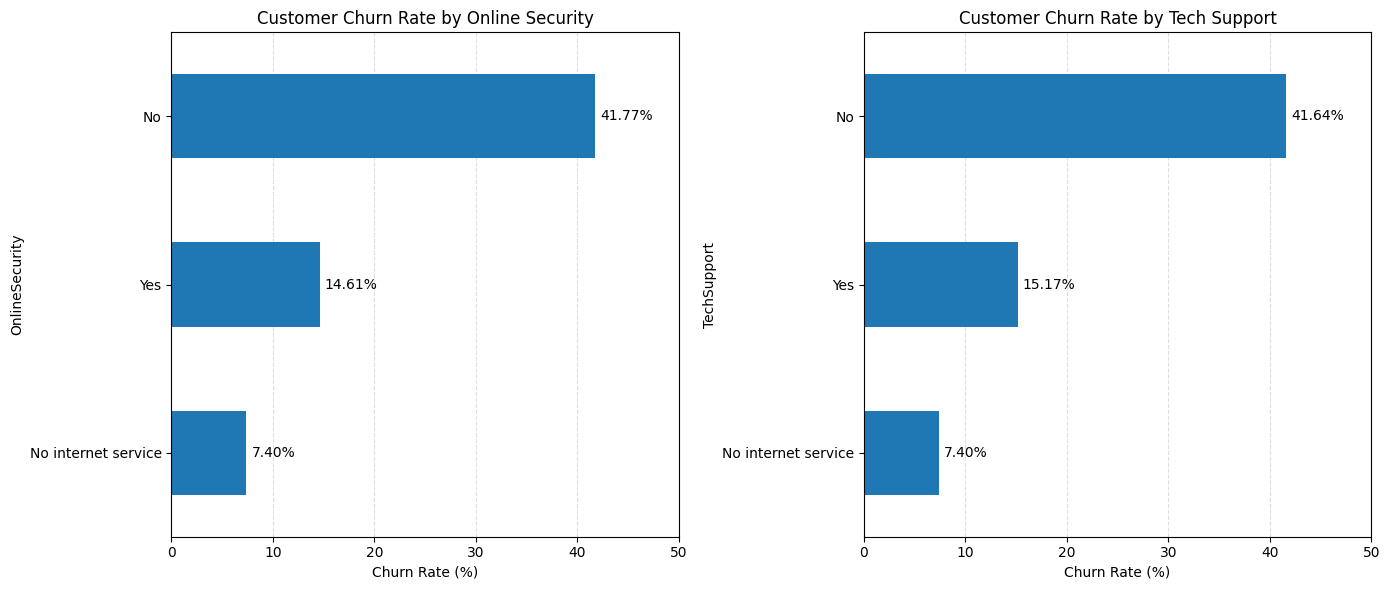

Chart saved successfully to: /Users/eironbatac/Desktop/DataAnalyticsPortfolio/projects/customer-churn-analysis/python/charts/churn_rate_security_tech_support.png


In [41]:

# Step 47: Visualize churn rates by online security and tech support

import matplotlib.pyplot as plt
from pathlib import Path

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

columns = [
    ("OnlineSecurity", "Customer Churn Rate by Online Security"),
    ("TechSupport", "Customer Churn Rate by Tech Support")
]

for ax, (column, title) in zip(axes, columns):
    rates = churn_by_security_support[column].sort_values()

    rates.plot(kind="barh", ax=ax)

    ax.set_title(title)
    ax.set_xlabel("Churn Rate (%)")
    ax.set_ylabel(column)
    ax.set_xlim(0, 50)
    ax.grid(axis="x", linestyle="--", alpha=0.4)
    ax.set_axisbelow(True)

    for index, value in enumerate(rates):
        ax.text(
            value + 0.5,
            index,
            f"{value:.2f}%",
            va="center"
        )

# Save the figure
chart_dir = Path.cwd().parent / "python" / "charts"
chart_dir.mkdir(parents=True, exist_ok=True)

chart_path = chart_dir / "churn_rate_security_tech_support.png"

fig.tight_layout()
fig.savefig(
    chart_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"Chart saved successfully to: {chart_path}")


Step 47 — Results and interpretation
Your analysis confirms two strong patterns in the customer churn dataset:
- Online security: Customers without online security have a churn rate of 41.77%, compared with 14.61% for customers who have it.
- Tech support: Customers without tech support have a churn rate of 41.64%, compared with 15.17% for customers who have it.
The differences are substantial: 27.16 percentage points for online security and 26.47 percentage points for tech support.

These findings suggest that customers who lack these additional services are important segments to investigate for retention opportunities. However, the analysis alone cannot establish that offering these services will cause churn to decrease.

In [42]:

# Step 48: Calculate churn rates by customer demographics

demographic_columns = [
    "gender",
    "SeniorCitizen",
    "Partner",
    "Dependents"
]

churn_by_demographics = {}

for column in demographic_columns:
    churn_rates = (
        df_clean.groupby(column, observed=True)["Churn"]
        .apply(lambda x: (x == "Yes").mean() * 100)
        .round(2)
        .sort_values(ascending=False)
    )

    churn_by_demographics[column] = churn_rates

    print(f"\nChurn Rate by {column} (%)")
    print(churn_rates)



Churn Rate by gender (%)
gender
Female    26.92
Male      26.16
Name: Churn, dtype: float64

Churn Rate by SeniorCitizen (%)
SeniorCitizen
1    41.68
0    23.61
Name: Churn, dtype: float64

Churn Rate by Partner (%)
Partner
No     32.96
Yes    19.66
Name: Churn, dtype: float64

Churn Rate by Dependents (%)
Dependents
No     31.28
Yes    15.45
Name: Churn, dtype: float64


Step 48 — Interpret the results
Customer demographic	Category	Churn rate
Gender	                Female	    26.92%
Gender	                Male	    26.16%
Senior citizen	        Yes (1)	    41.68%
Senior citizen	        No (0)	    23.61%
Partner	                No	        32.96%
Partner	                Yes	        19.66%
Dependents	            No	        31.28%
Dependents	            Yes	        15.45%

Key insights
- Senior citizens: The churn rate is 41.68%, compared with 23.61% for non-senior customers — a difference of 18.07 percentage points.
- Partner status: Customers without partners have a 32.96% churn rate, compared with 19.66% for customers with partners.
- Dependents: Customers without dependents have a 31.28% churn rate, compared with 15.45% for those with dependents.
- Gender: Female and male churn rates are relatively close, differing by only 0.76 percentage points.

The largest demographic differences are associated with senior-citizen status and dependents. These patterns can help us identify customer segments for further investigation, but they do not establish causation.

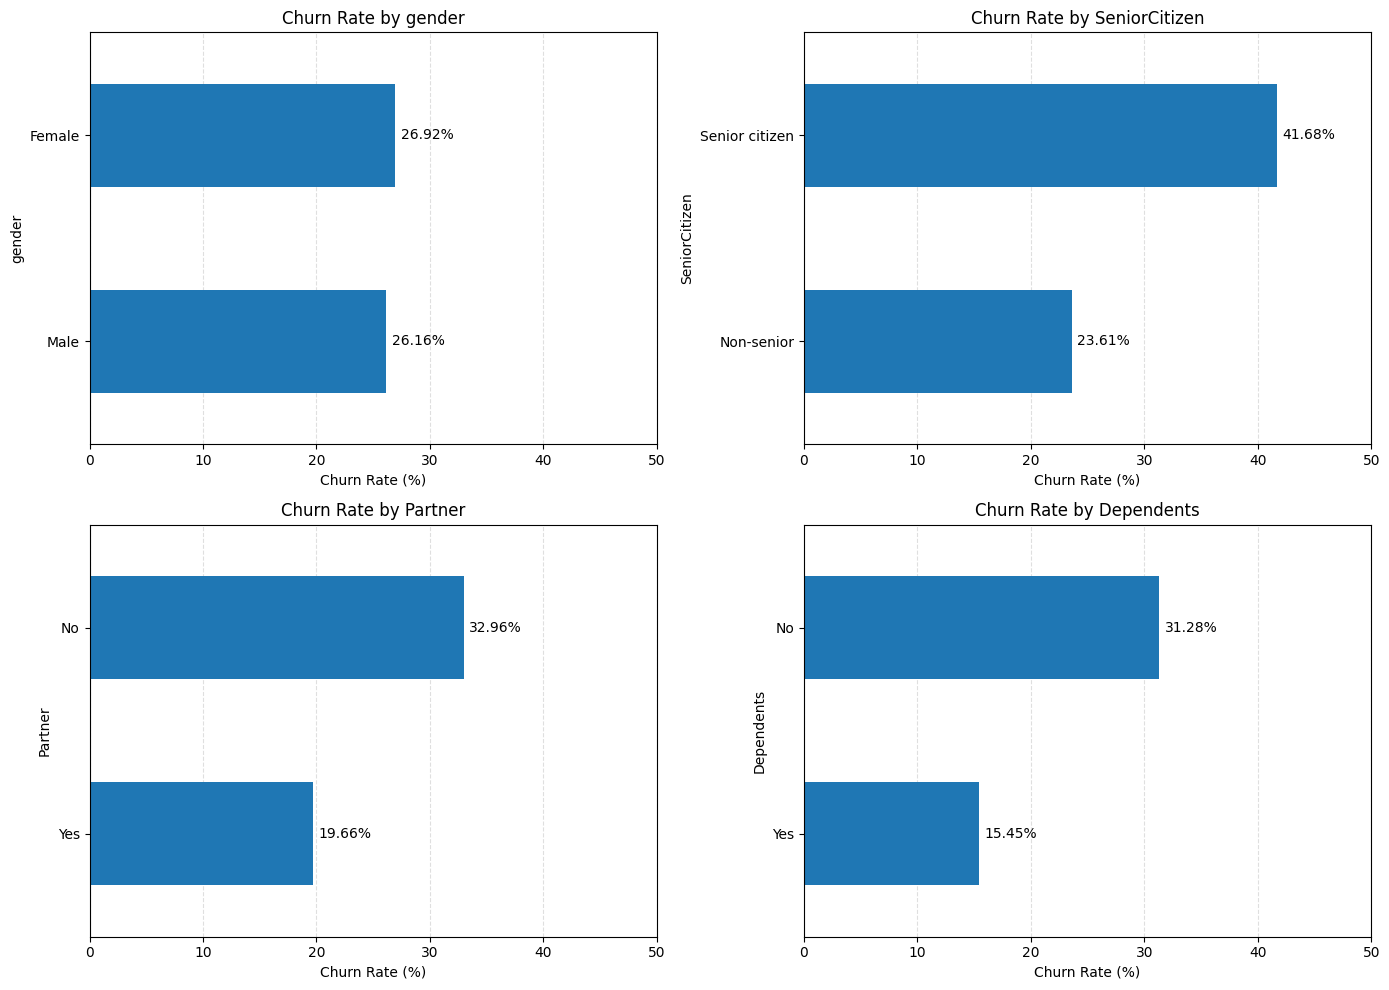

Chart saved successfully to: /Users/eironbatac/Desktop/DataAnalyticsPortfolio/projects/customer-churn-analysis/python/charts/churn_rate_by_demographics.png


In [43]:

# Step 49: Visualize customer churn rates by demographics

import matplotlib.pyplot as plt
from pathlib import Path

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, column in zip(axes.flat, demographic_columns):
    rates = churn_by_demographics[column].sort_values()

    # Use readable labels for senior-citizen status
    if column == "SeniorCitizen":
        rates.index = rates.index.map({
            0: "Non-senior",
            1: "Senior citizen"
        })

    rates.plot(kind="barh", ax=ax)

    ax.set_title(f"Churn Rate by {column}")
    ax.set_xlabel("Churn Rate (%)")
    ax.set_ylabel(column)
    ax.set_xlim(0, 50)
    ax.grid(axis="x", linestyle="--", alpha=0.4)
    ax.set_axisbelow(True)

    for index, value in enumerate(rates):
        ax.text(
            value + 0.5,
            index,
            f"{value:.2f}%",
            va="center"
        )

# Save the combined figure
chart_dir = Path.cwd().parent / "python" / "charts"
chart_dir.mkdir(parents=True, exist_ok=True)

chart_path = chart_dir / "churn_rate_by_demographics.png"

fig.tight_layout()
fig.savefig(
    chart_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"Chart saved successfully to: {chart_path}")


In [44]:

# Step 50: Validate the final customer churn analysis

# 1. Check the dataset dimensions
print("Dataset dimensions:", df_clean.shape)

# 2. Check for missing values
print("\nMissing values:")
print(df_clean.isnull().sum().sum())

# 3. Check for duplicate rows
print("\nDuplicate rows:", df_clean.duplicated().sum())

# 4. Check customer counts by churn status
print("\nCustomer counts by churn status:")
print(df_clean["Churn"].value_counts())

# 5. Calculate the overall churn rate
overall_churn_rate = (
    (df_clean["Churn"] == "Yes").mean() * 100
)

print(f"\nOverall churn rate: {overall_churn_rate:.2f}%")

# 6. Display the demographic churn rates
print("\nChurn rates by demographic group:")
for column in demographic_columns:
    print(f"\n{column}:")
    print(churn_by_demographics[column].round(2))


Dataset dimensions: (7043, 23)

Missing values:
11

Duplicate rows: 0

Customer counts by churn status:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Overall churn rate: 26.54%

Churn rates by demographic group:

gender:
gender
Female    26.92
Male      26.16
Name: Churn, dtype: float64

SeniorCitizen:
SeniorCitizen
1    41.68
0    23.61
Name: Churn, dtype: float64

Partner:
Partner
No     32.96
Yes    19.66
Name: Churn, dtype: float64

Dependents:
Dependents
No     31.28
Yes    15.45
Name: Churn, dtype: float64


In [45]:

# Step 51: Investigate missing values in the cleaned dataset

# Count missing values in each column
missing_by_column = df_clean.isnull().sum()

print("Columns with missing values:")
print(missing_by_column[missing_by_column > 0])

# Display the affected records
missing_rows = df_clean[df_clean.isnull().any(axis=1)]

print("\nNumber of records with missing values:", len(missing_rows))

# Show relevant columns if they exist in the dataset
inspect_columns = [
    column
    for column in ["customerID", "tenure", "TotalCharges", "Churn"]
    if column in df_clean.columns
]

display(missing_rows[inspect_columns])

# Check whether customer IDs are unique
if "customerID" in df_clean.columns:
    print(
        "\nDuplicate customer IDs:",
        df_clean["customerID"].duplicated().sum()
    )


Columns with missing values:
TotalCharges    11
dtype: int64

Number of records with missing values: 11


,customerID,tenure,TotalCharges,Churn
488,4472-LVYGI,0,NaN,No
753,3115-CZMZD,0,NaN,No
936,5709-LVOEQ,0,NaN,No
1082,4367-NUYAO,0,NaN,No
1340,1371-DWPAZ,0,NaN,No
3331,7644-OMVMY,0,NaN,No
3826,3213-VVOLG,0,NaN,No
4380,2520-SGTTA,0,NaN,No
5218,2923-ARZLG,0,NaN,No
6670,4075-WKNIU,0,NaN,No



Duplicate customer IDs: 0


In [46]:

# Step 50: Verify detailed demographic churn rates against Tableau

demographic_group_columns = [
    "gender",
    "SeniorCitizen",
    "Partner",
    "Dependents"
]

# Calculate churn rate for each demographic combination
churn_by_demographic_group = (
    df_clean
    .groupby(demographic_group_columns, observed=True)
    .agg(
        Customers=("Churn", "size"),
        Churned=("Churn", lambda values: (values == "Yes").sum())
    )
    .reset_index()
)

churn_by_demographic_group["Churn Rate (%)"] = (
    churn_by_demographic_group["Churned"]
    / churn_by_demographic_group["Customers"]
    * 100
)

# Make SeniorCitizen easier to read
churn_by_demographic_group["SeniorCitizen"] = (
    churn_by_demographic_group["SeniorCitizen"]
    .map({0: "Non-senior", 1: "Senior citizen"})
)

# Display the detailed results
churn_by_demographic_group = churn_by_demographic_group.sort_values(
    demographic_group_columns
).reset_index(drop=True)

display(
    churn_by_demographic_group.round({"Churn Rate (%)": 2})
)


,gender,SeniorCitizen,Partner,Dependents,Customers,Churned,Churn Rate (%)
0,Female,Non-senior,No,No,1338,429,32.06
1,Female,Non-senior,No,Yes,142,32,22.54
2,Female,Non-senior,Yes,No,596,114,19.13
3,Female,Non-senior,Yes,Yes,844,124,14.69
4,Female,Senior citizen,No,No,317,158,49.84
5,Female,Senior citizen,No,Yes,3,1,33.33
6,Female,Senior citizen,Yes,No,209,73,34.93
7,Female,Senior citizen,Yes,Yes,39,8,20.51
8,Male,Non-senior,No,No,1381,418,30.27
9,Male,Non-senior,No,Yes,211,43,20.38
